# **Elliptic++ Dataset Overview**

This notebook provides a structured overview of the **Elliptic++ Actors and Transactions datasets** used in the project.

The notebook is adapted from the supplied `Elliptic++_Actors_ActorInteraction_Graph_Viz.ipynb`, `Elliptic++_Actors_Dataset_Statistics.ipynb` and `Elliptic++_Transactions_Dataset_Statistics.ipynb` samples, but uses the project's local directory structure:

- `data/Actors_Dataset/`
- `data/Transactions_Dataset/`

The goal is to document the available files, inspect their schema, examine representative records, summarize class labels, inspect the actor-interaction graph, and analyze the numeric features that drive illicit/licit classification for both actors (wallets) and transactions.

## Dataset source and citation

**Elliptic++** was released by Youssef Elmougy and Ling Liu, Georgia Institute of Technology.

GitHub repository: <https://github.com/git-disl/EllipticPlusPlus>

Reference paper:

> Youssef Elmougy and Ling Liu. 2023. *Demystifying Fraudulent Transactions and Illicit Nodes in the Bitcoin Network for Financial Forensics.*

**Note:** In the Actors dataset, an **actor** represents a Bitcoin wallet address. Class labels used throughout the dataset (and this notebook) are:

| Code | Meaning |
| --- | --- |
| `1` | Illicit |
| `2` | Licit |
| `3` | Unknown |

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")


ACTOR_DIR = Path("data/Actors_Dataset")
TRANSACTION_DIR = Path("data/Transactions_Dataset")

print(f"Actor Direction -> {ACTOR_DIR} | existed: {ACTOR_DIR.exists()}")
print(f"Transaction Direction -> {TRANSACTION_DIR} | existed: {TRANSACTION_DIR.exists()}")

Actor Direction -> data/Actors_Dataset | existed: True
Transaction Direction -> data/Transactions_Dataset | existed: True


## Dataset files discovered

In [2]:
def show_file_inventory(paths: dict, dataset_name: str) -> pd.DataFrame:
    rows = []
    for path in sorted(paths.values()):
        size_mb = path.stat().st_size / (1024 * 1024)
        rows.append({
            "dataset": dataset_name,
            "file": path.name,
            "path": str(path),
            "size_mb": round(size_mb, 2),
        })

    inventory = pd.DataFrame(rows)
    if inventory.empty:
        print(f"No CSV files found in {dataset_name}.")
    else:
        display(inventory)

    return inventory


actor_paths = {}
for path in ACTOR_DIR.rglob("*.csv"):
    actor_paths[path.stem] = path

transaction_paths = {}
for path in TRANSACTION_DIR.rglob("*.csv"):
    transaction_paths[path.stem] = path

actor_inventory = show_file_inventory(actor_paths, "Actors")
transaction_inventory = show_file_inventory(transaction_paths, "Transactions")

,dataset,file,path,size_mb
0,Actors,AddrAddr_edgelist.csv,data/Actors_Dataset/AddrAddr_edgelist.csv,191.34
1,Actors,AddrTx_edgelist.csv,data/Actors_Dataset/AddrTx_edgelist.csv,20.26
2,Actors,TxAddr_edgelist.csv,data/Actors_Dataset/TxAddr_edgelist.csv,35.00
3,Actors,wallets_classes.csv,data/Actors_Dataset/wallets_classes.csv,29.01
4,Actors,wallets_features.csv,data/Actors_Dataset/wallets_features.csv,578.37
5,Actors,wallets_features_classes_combined.csv,data/Actors_Dataset/wallets_features_classes_c...,580.79


,dataset,file,path,size_mb
0,Transactions,txs_classes.csv,data/Transactions_Dataset/txs_classes.csv,2.25
1,Transactions,txs_edgelist.csv,data/Transactions_Dataset/txs_edgelist.csv,4.26
2,Transactions,txs_features.csv,data/Transactions_Dataset/txs_features.csv,662.60


## Actors Dataset Overview

The sample notebooks work with the main Actors files:

- `wallets_features.csv` — numeric features per wallet address per time step
- `wallets_classes.csv` — one class label (`1`=illicit, `2`=licit, `3`=unknown) per address
- `AddrAddr_edgelist.csv` — actor/actor interaction graph
- `AddrTx_edgelist.csv` — address/transaction graph
- `TxAddr_edgelist.csv` — reverse address/transaction representation
- `wallets_features_classes_combined.csv` — convenience table combining features and classes

In [3]:
def load_csv_if_present(paths: dict, stem: str):
    path = paths.get(stem)
    if path is None:
        print(f"{stem}.csv not found.")
        return None

    df = pd.read_csv(path)
    print(f"{stem}.csv -> shape={df.shape}")
    display(df.head())
    return df


df_wallets_features = load_csv_if_present(actor_paths, "wallets_features")
df_wallets_classes = load_csv_if_present(actor_paths, "wallets_classes")
df_AddrAddr_edgelist = load_csv_if_present(actor_paths, "AddrAddr_edgelist")
df_AddrTx_edgelist = load_csv_if_present(actor_paths, "AddrTx_edgelist")
df_TxAddr_edgelist = load_csv_if_present(actor_paths, "TxAddr_edgelist")
df_wallets_features_classes_combined = load_csv_if_present(
    actor_paths, "wallets_features_classes_combined"
)

wallets_features.csv -> shape=(1268260, 57)


,address,Time step,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs,first_sent_block,first_received_block,num_timesteps_appeared_in,btc_transacted_total,btc_transacted_min,btc_transacted_max,btc_transacted_mean,btc_transacted_median,btc_sent_total,btc_sent_min,btc_sent_max,btc_sent_mean,btc_sent_median,btc_received_total,btc_received_min,btc_received_max,btc_received_mean,btc_received_median,fees_total,fees_min,fees_max,fees_mean,fees_median,fees_as_share_total,fees_as_share_min,fees_as_share_max,fees_as_share_mean,fees_as_share_median,blocks_btwn_txs_total,blocks_btwn_txs_min,blocks_btwn_txs_max,blocks_btwn_txs_mean,blocks_btwn_txs_median,blocks_btwn_input_txs_total,blocks_btwn_input_txs_min,blocks_btwn_input_txs_max,blocks_btwn_input_txs_mean,blocks_btwn_input_txs_median,blocks_btwn_output_txs_total,blocks_btwn_output_txs_min,blocks_btwn_output_txs_max,blocks_btwn_output_txs_mean,blocks_btwn_output_txs_median,num_addr_transacted_multiple,transacted_w_address_total,transacted_w_address_min,transacted_w_address_max,transacted_w_address_mean,transacted_w_address_median
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,0.0,1.0,439586.0,439586.0,0.0,1.0,0.0,439586.0,1.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.0,0.0,0.0,0.0,0.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.007042,0.007042,0.007042,0.007042,0.007042,0.000012,0.000012,0.000012,0.000012,0.000012,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,24.0,1.0,1.0,1.0,1.0
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,25,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
2,1111DAYXhoxZx2tsRnzimfozo783x1yC2,29,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
3,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
4,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0


wallets_classes.csv -> shape=(822942, 2)


,address,class
0,111112TykSw72ztDN2WJger4cynzWYC5w,2
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,3
2,1111VHuXEzHaRCgXbVwojtaP7Co3QABb,2
3,111218KKkh1JJFRHbwM16AwCiVCc4m7he1,3
4,1115LWW3xsD9jT9VRY7viCN9S34RVAAuA,2


AddrAddr_edgelist.csv -> shape=(2868964, 2)


...

,input_address,txId
0,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a,230325127
1,13Lhad3SAmu2vqYg2dxbNcxH7LE77kJu2w,230325139
2,1MAQQZn7EHP6J3erXByCciFiVcgS8ZhWqz,86875675
3,16zs5SVSyADh5WrLNbZbpRLsBsN5uEzgeK,230325147
4,1QJpwtUorBKPGUJkSyrRcBKTAHq4CXrdYh,230325154


TxAddr_edgelist.csv -> shape=(837124, 2)


,txId,output_address
0,230325127,1GASxu5nMntiRKdVtTVRvEbP965G51bhHH
1,230325127,14YRXHHof4BY1TVxN5FqYPcEdpmXiYT78a
2,230325139,1GFdrdgtG34GChM8SMpMwcXFc4nYbH1A5G
3,86875675,19q57SeCEzTnWrWVXA43nZzhSiXkYggh7c
4,86875675,1Kk1NVYnCE8ALXDhgMM6HqTt1jDSvi6QBA


wallets_features_classes_combined.csv -> shape=(1268260, 58)


,address,Time step,class,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs,first_sent_block,first_received_block,num_timesteps_appeared_in,btc_transacted_total,btc_transacted_min,btc_transacted_max,btc_transacted_mean,btc_transacted_median,btc_sent_total,btc_sent_min,btc_sent_max,btc_sent_mean,btc_sent_median,btc_received_total,btc_received_min,btc_received_max,btc_received_mean,btc_received_median,fees_total,fees_min,fees_max,fees_mean,fees_median,fees_as_share_total,fees_as_share_min,fees_as_share_max,fees_as_share_mean,fees_as_share_median,blocks_btwn_txs_total,blocks_btwn_txs_min,blocks_btwn_txs_max,blocks_btwn_txs_mean,blocks_btwn_txs_median,blocks_btwn_input_txs_total,blocks_btwn_input_txs_min,blocks_btwn_input_txs_max,blocks_btwn_input_txs_mean,blocks_btwn_input_txs_median,blocks_btwn_output_txs_total,blocks_btwn_output_txs_min,blocks_btwn_output_txs_max,blocks_btwn_output_txs_mean,blocks_btwn_output_txs_median,num_addr_transacted_multiple,transacted_w_address_total,transacted_w_address_min,transacted_w_address_max,transacted_w_address_mean,transacted_w_address_median
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,2,0.0,1.0,439586.0,439586.0,0.0,1.0,0.0,439586.0,1.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.0,0.0,0.0,0.0,0.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.007042,0.007042,0.007042,0.007042,0.007042,0.000012,0.000012,0.000012,0.000012,0.000012,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,24.0,1.0,1.0,1.0,1.0
1,1111DAYXhoxZx2tsRnzimfozo783x1yC2,25,3,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
2,1111DAYXhoxZx2tsRnzimfozo783x1yC2,29,3,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
3,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,3,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0
4,1111DAYXhoxZx2tsRnzimfozo783x1yC2,39,3,0.0,8.0,439589.0,485959.0,46370.0,8.0,0.0,439589.0,6.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.0,0.0,0.0,0.0,0.0,0.273046,0.003900,0.133777,0.034131,0.014352,0.002371,0.000122,0.000580,0.000296,0.000242,0.002217,0.000121,0.000523,0.000277,0.000237,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,0.0,0.0,0.0,0.0,46370.0,0.0,20164.0,6624.285714,8060.0,0.0,8.0,1.0,1.0,1.0,1.0


### Structure of the main Actors tables

In [4]:
actor_frames = {
    "wallets_features": df_wallets_features,
    "wallets_classes": df_wallets_classes,
    "AddrAddr_edgelist": df_AddrAddr_edgelist,
    "AddrTx_edgelist": df_AddrTx_edgelist,
    "TxAddr_edgelist": df_TxAddr_edgelist,
    "wallets_features_classes_combined": df_wallets_features_classes_combined,
}

actor_schema_rows = []
for name, df in actor_frames.items():
    if df is None:
        continue

    actor_schema_rows.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
    })

actor_schema = pd.DataFrame(actor_schema_rows)
display(actor_schema)

,table,rows,columns,missing_cells,duplicate_rows
0,wallets_features,1268260,57,0,347569
1,wallets_classes,822942,2,0,0
2,AddrAddr_edgelist,2868964,2,0,84620
3,AddrTx_edgelist,477117,2,0,0
4,TxAddr_edgelist,837124,2,0,0
5,wallets_features_classes_combined,1268260,58,0,347569


### Columns and data types

In [5]:
for name, df in actor_frames.items():
    if df is None:
        continue

    print(f"\n{name}")
    schema = pd.DataFrame({
        "column": df.columns,
        "dtype": [str(dtype) for dtype in df.dtypes],
        "missing": [int(df[col].isna().sum()) for col in df.columns],
        "n_unique": [int(df[col].nunique(dropna=True)) for col in df.columns],
    })
    display(schema)


wallets_features


,column,dtype,missing,n_unique
0,address,str,0,822942
1,Time step,int64,0,49
2,num_txs_as_sender,float64,0,162
3,num_txs_as receiver,float64,0,114
4,first_block_appeared_in,float64,0,473
5,last_block_appeared_in,float64,0,473
6,lifetime_in_blocks,float64,0,1087
7,total_txs,float64,0,193
8,first_sent_block,float64,0,474
9,first_received_block,float64,0,474



wallets_classes


,column,dtype,missing,n_unique
0,address,str,0,822942
1,class,int64,0,3



AddrAddr_edgelist


...

,column,dtype,missing,n_unique
0,input_address,str,0,400212
1,txId,int64,0,202804



TxAddr_edgelist


,column,dtype,missing,n_unique
0,txId,int64,0,202804
1,output_address,str,0,641043



wallets_features_classes_combined


,column,dtype,missing,n_unique
0,address,str,0,822942
1,Time step,int64,0,49
2,class,int64,0,3
3,num_txs_as_sender,float64,0,162
4,num_txs_as receiver,float64,0,114
5,first_block_appeared_in,float64,0,473
6,last_block_appeared_in,float64,0,473
7,lifetime_in_blocks,float64,0,1087
8,total_txs,float64,0,193
9,first_sent_block,float64,0,474


### Example actor inspection

Following the sample notebook's walkthrough of a single address, the cell below
picks a representative actor and shows its row in every Actors table it appears
in, plus the transactions it is linked to through `AddrTx_edgelist` /
`TxAddr_edgelist`.

In [6]:
example_address = None
if df_wallets_classes is not None and not df_wallets_classes.empty:
    example_address = df_wallets_classes["address"].iloc[0]
elif df_wallets_features is not None and not df_wallets_features.empty:
    example_address = df_wallets_features["address"].iloc[0]

if example_address is None:
    print("No actor address available to inspect.")
else:
    print(f"Example address: {example_address}\n")

    if df_wallets_features is not None:
        print("wallets_features.csv rows for this address:")
        display(df_wallets_features[df_wallets_features["address"] == example_address])

    if df_wallets_classes is not None:
        print("wallets_classes.csv row for this address:")
        display(df_wallets_classes[df_wallets_classes["address"] == example_address])

    if df_wallets_features_classes_combined is not None:
        print("wallets_features_classes_combined.csv rows for this address:")
        display(
            df_wallets_features_classes_combined[
                df_wallets_features_classes_combined["address"] == example_address
            ]
        )

    if df_AddrTx_edgelist is not None:
        outgoing = df_AddrTx_edgelist[df_AddrTx_edgelist["input_address"] == example_address]
        print(f"Transactions this address sent to (AddrTx_edgelist): {len(outgoing)}")
        display(outgoing.head())

    if df_TxAddr_edgelist is not None:
        incoming = df_TxAddr_edgelist[df_TxAddr_edgelist["output_address"] == example_address]
        print(f"Transactions this address received from (TxAddr_edgelist): {len(incoming)}")
        display(incoming.head())

Example address: 111112TykSw72ztDN2WJger4cynzWYC5w

wallets_features.csv rows for this address:


,address,Time step,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs,first_sent_block,first_received_block,num_timesteps_appeared_in,btc_transacted_total,btc_transacted_min,btc_transacted_max,btc_transacted_mean,btc_transacted_median,btc_sent_total,btc_sent_min,btc_sent_max,btc_sent_mean,btc_sent_median,btc_received_total,btc_received_min,btc_received_max,btc_received_mean,btc_received_median,fees_total,fees_min,fees_max,fees_mean,fees_median,fees_as_share_total,fees_as_share_min,fees_as_share_max,fees_as_share_mean,fees_as_share_median,blocks_btwn_txs_total,blocks_btwn_txs_min,blocks_btwn_txs_max,blocks_btwn_txs_mean,blocks_btwn_txs_median,blocks_btwn_input_txs_total,blocks_btwn_input_txs_min,blocks_btwn_input_txs_max,blocks_btwn_input_txs_mean,blocks_btwn_input_txs_median,blocks_btwn_output_txs_total,blocks_btwn_output_txs_min,blocks_btwn_output_txs_max,blocks_btwn_output_txs_mean,blocks_btwn_output_txs_median,num_addr_transacted_multiple,transacted_w_address_total,transacted_w_address_min,transacted_w_address_max,transacted_w_address_mean,transacted_w_address_median
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,0.0,1.0,439586.0,439586.0,0.0,1.0,0.0,439586.0,1.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.0,0.0,0.0,0.0,0.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.007042,0.007042,0.007042,0.007042,0.007042,0.000012,0.000012,0.000012,0.000012,0.000012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,1.0,1.0,1.0,1.0


wallets_classes.csv row for this address:


,address,class
0,111112TykSw72ztDN2WJger4cynzWYC5w,2


wallets_features_classes_combined.csv rows for this address:


,address,Time step,class,num_txs_as_sender,num_txs_as receiver,first_block_appeared_in,last_block_appeared_in,lifetime_in_blocks,total_txs,first_sent_block,first_received_block,num_timesteps_appeared_in,btc_transacted_total,btc_transacted_min,btc_transacted_max,btc_transacted_mean,btc_transacted_median,btc_sent_total,btc_sent_min,btc_sent_max,btc_sent_mean,btc_sent_median,btc_received_total,btc_received_min,btc_received_max,btc_received_mean,btc_received_median,fees_total,fees_min,fees_max,fees_mean,fees_median,fees_as_share_total,fees_as_share_min,fees_as_share_max,fees_as_share_mean,fees_as_share_median,blocks_btwn_txs_total,blocks_btwn_txs_min,blocks_btwn_txs_max,blocks_btwn_txs_mean,blocks_btwn_txs_median,blocks_btwn_input_txs_total,blocks_btwn_input_txs_min,blocks_btwn_input_txs_max,blocks_btwn_input_txs_mean,blocks_btwn_input_txs_median,blocks_btwn_output_txs_total,blocks_btwn_output_txs_min,blocks_btwn_output_txs_max,blocks_btwn_output_txs_mean,blocks_btwn_output_txs_median,num_addr_transacted_multiple,transacted_w_address_total,transacted_w_address_min,transacted_w_address_max,transacted_w_address_mean,transacted_w_address_median
0,111112TykSw72ztDN2WJger4cynzWYC5w,25,2,0.0,1.0,439586.0,439586.0,0.0,1.0,0.0,439586.0,1.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.0,0.0,0.0,0.0,0.0,0.010628,0.010628,0.010628,0.010628,0.010628,0.007042,0.007042,0.007042,0.007042,0.007042,0.000012,0.000012,0.000012,0.000012,0.000012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.0,1.0,1.0,1.0,1.0


Transactions this address sent to (AddrTx_edgelist): 0


,input_address,txId


Transactions this address received from (TxAddr_edgelist): 1


,txId,output_address
456694,15329918,111112TykSw72ztDN2WJger4cynzWYC5w


## Actors features

The supplied sample describes the Actors features as containing a class label together with
transaction-related and time-related features. The following cells inspect the actual columns
available in the local file, separate identifier/time/label columns from numeric candidate
features, and summarize their distributions for later analysis.

In [7]:
NON_FEATURE_COLUMNS = {"address", "txId", "class", "Time step", "time_step"}

if df_wallets_features is not None:
    print("wallets_features.csv columns:")
    for col in df_wallets_features.columns:
        print(f"- {col}")

    actor_numeric_columns = [
        col
        for col in df_wallets_features.select_dtypes(include=np.number).columns
        if col not in NON_FEATURE_COLUMNS
    ]

    print(f"\nNumeric feature columns: {len(actor_numeric_columns)}")
    print(actor_numeric_columns)

    print("\nSummary statistics (first 15 numeric features):")
    display(df_wallets_features[actor_numeric_columns[:15]].describe().T)
else:
    actor_numeric_columns = []

wallets_features.csv columns:
- address
- Time step
- num_txs_as_sender
- num_txs_as receiver
- first_block_appeared_in
- last_block_appeared_in
- lifetime_in_blocks
- total_txs
- first_sent_block
- first_received_block
- num_timesteps_appeared_in
- btc_transacted_total
- btc_transacted_min
- btc_transacted_max
- btc_transacted_mean
- btc_transacted_median
- btc_sent_total
- btc_sent_min
- btc_sent_max
- btc_sent_mean
- btc_sent_median
- btc_received_total
- btc_received_min
- btc_received_max
- btc_received_mean
- btc_received_median
- fees_total
- fees_min
- fees_max
- fees_mean
- fees_median
- fees_as_share_total
- fees_as_share_min
- fees_as_share_max
- fees_as_share_mean
- fees_as_share_median
- blocks_btwn_txs_total
- blocks_btwn_txs_min
- blocks_btwn_txs_max
- blocks_btwn_txs_mean
- blocks_btwn_txs_median
- blocks_btwn_input_txs_total
- blocks_btwn_input_txs_min
- blocks_btwn_input_txs_max
- blocks_btwn_input_txs_mean
- blocks_btwn_input_txs_median
- blocks_btwn_output_txs_total

,count,mean,std,min,25%,50%,75%,max
num_txs_as_sender,1268260.0,12.700380,88.672574,0.0,0.000000,1.000000,1.000000,1453.000000
num_txs_as receiver,1268260.0,6.566587,45.825422,0.0,1.000000,1.000000,1.000000,548.000000
first_block_appeared_in,1268260.0,434992.480395,30941.598656,391200.0,405321.000000,431529.000000,463777.000000,487975.000000
last_block_appeared_in,1268260.0,440748.706196,30564.465158,391200.0,411363.000000,439589.000000,469828.000000,487975.000000
lifetime_in_blocks,1268260.0,5756.225801,16905.687625,0.0,0.000000,0.000000,5.000000,96775.000000
total_txs,1268260.0,19.266962,116.423712,1.0,1.000000,2.000000,2.000000,1471.000000
first_sent_block,1268260.0,258239.879048,214962.835050,0.0,0.000000,397257.000000,441606.000000,487975.000000
first_received_block,1268260.0,361634.205947,164693.333071,0.0,395232.000000,419429.000000,459747.000000,487975.000000
num_timesteps_appeared_in,1268260.0,1.871110,3.898093,1.0,1.000000,1.000000,1.000000,47.000000
btc_transacted_total,1268260.0,148.103727,1471.961996,0.0,0.005115,0.044772,0.530853,32412.300000


## Label helpers

The class/label column and its color coding are used repeatedly below (class distribution,
time-step charts, feature-correlation charts and the actor-interaction graph), so they are
defined once here. Class codes are tolerant of either the numeric encoding (`1`/`2`/`3`) or
string names (`illicit`/`licit`/`unknown`).

In [8]:
CLASS_COLOR_MAP = {
    "1": "#d62728",        # illicit
    "illicit": "#d62728",
    "2": "#2ca02c",        # licit
    "licit": "#2ca02c",
    "3": "#7f7f7f",        # unknown
    "unknown": "#7f7f7f",
}
CLASS_LABEL_MAP = {
    "1": "Illicit",
    "illicit": "Illicit",
    "2": "Licit",
    "licit": "Licit",
    "3": "Unknown",
    "unknown": "Unknown",
}
NO_LABEL_COLOR = "#c7c7c7"
NO_LABEL_NAME = "No label"


def resolve_class_color(label):
    if label is None or (isinstance(label, float) and pd.isna(label)):
        return NO_LABEL_COLOR
    return CLASS_COLOR_MAP.get(str(label).strip().lower(), NO_LABEL_COLOR)


def resolve_class_name(label):
    if label is None or (isinstance(label, float) and pd.isna(label)):
        return NO_LABEL_NAME
    key = str(label).strip().lower()
    return CLASS_LABEL_MAP.get(key, f"Class {label}")


def detect_column(df, candidates):
    if df is None:
        return None
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    return None


def build_address_class_map(combined_df, class_column):
    """Map each address to its raw class/label value from the combined actor table."""
    if combined_df is None or class_column is None:
        return {}

    return (
        combined_df.dropna(subset=["address", class_column])
        .drop_duplicates(subset="address")
        .set_index("address")[class_column]
        .to_dict()
    )


# Resolve the columns used throughout the rest of the Actors section.
combined_df = df_wallets_features_classes_combined
class_column = detect_column(combined_df, ["class", "Class", "label", "Label"])
time_column = detect_column(combined_df, ["Time step", "time_step", "TimeStep", "timestep"])

print(f"class_column = {class_column!r}")
print(f"time_column  = {time_column!r}")

class_column = 'class'
time_column  = 'Time step'


## Class distribution

,class,count,percentage,label_name
0,1,14266,1.73,Illicit
1,2,251088,30.51,Licit
2,3,557588,67.76,Unknown


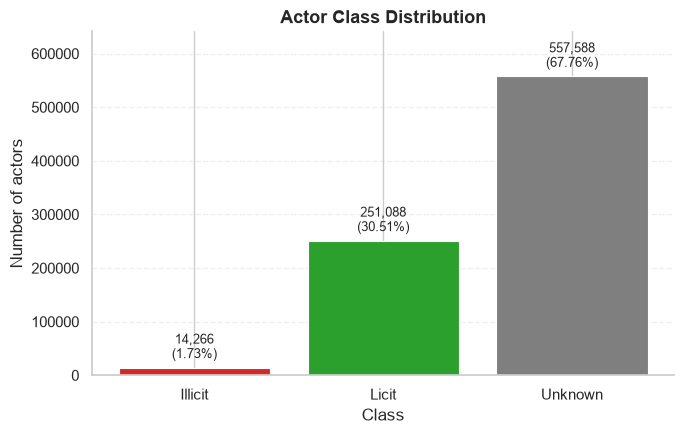

In [9]:
if df_wallets_classes is None or class_column is None:
    print("Class information is not available.")
else:
    class_counts = (
        df_wallets_classes[class_column]
        .value_counts(dropna=False)
        .rename_axis(class_column)
        .reset_index(name="count")
        .sort_values(class_column)
        .reset_index(drop=True)
    )
    class_counts["percentage"] = (
        class_counts["count"] / class_counts["count"].sum() * 100
    ).round(2)
    class_counts["label_name"] = class_counts[class_column].apply(resolve_class_name)
    display(class_counts)

    colors = class_counts[class_column].apply(resolve_class_color)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(
        class_counts["label_name"], class_counts["count"],
        color=colors, edgecolor="white", linewidth=0.8,
    )

    for bar, count, pct in zip(bars, class_counts["count"], class_counts["percentage"]):
        ax.annotate(
            f"{count:,}\n({pct}%)",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4), textcoords="offset points",
            ha="center", va="bottom", fontsize=9,
        )

    ax.set_title("Actor Class Distribution", fontsize=13, weight="bold")
    ax.set_xlabel(class_column.capitalize())
    ax.set_ylabel("Number of actors")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(y=0.15)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

### Actors by time step

class,1,2,3,Total
Time step,,,,
1,96,24547,26465,51108
2,99,16292,15878,32269
3,58,4835,26213,31106
4,266,8647,31035,39948
5,54,10465,24621,35140
6,17,1957,17029,19003
7,463,7902,23357,31722
8,267,16229,17631,34127
9,960,3894,23819,28673


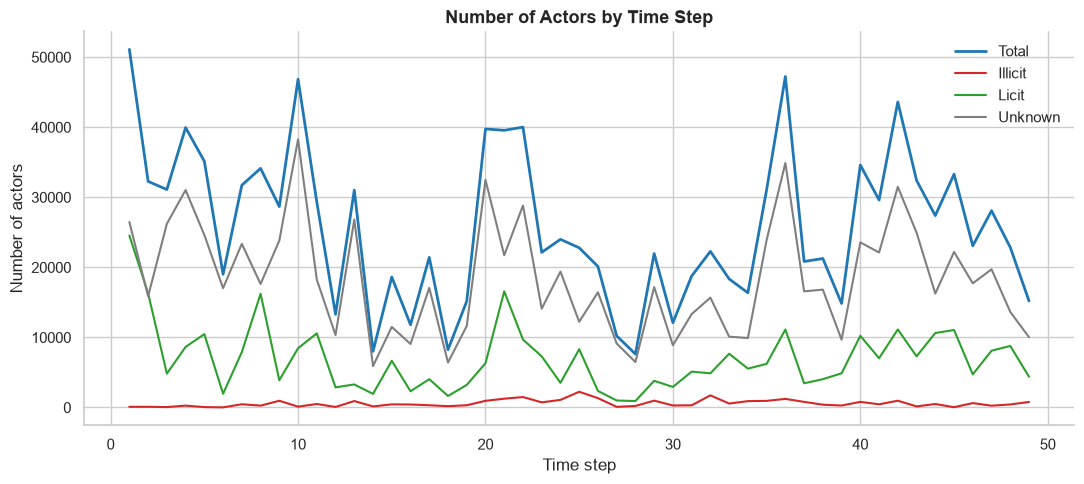

In [10]:
if combined_df is None or time_column is None or class_column is None:
    print("A combined actor table with time-step and class columns is required.")
else:
    grouped_class = (
        combined_df[[time_column, class_column]]
        .groupby([time_column, class_column])
        .size()
        .rename("count")
        .reset_index()
    )

    pivot = grouped_class.pivot(index=time_column, columns=class_column, values="count").fillna(0)
    pivot["Total"] = pivot.sum(axis=1)
    display(pivot.head(10))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(pivot.index, pivot["Total"], color="#1f77b4", label="Total", linewidth=2)
    for label_value in pivot.columns:
        if label_value == "Total":
            continue
        ax.plot(
            pivot.index, pivot[label_value],
            color=resolve_class_color(label_value),
            label=resolve_class_name(label_value),
            linewidth=1.5,
        )

    ax.set_title("Number of Actors by Time Step", fontsize=13, weight="bold")
    ax.set_xlabel(time_column)
    ax.set_ylabel("Number of actors")
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

### Illicit actor persistence across time steps

Following the sample statistics notebook, this section buckets illicit actors by how many
distinct time steps they transact in: exactly 1, between 2 and 4, or 5 or more.

,illicit_actor_count
Time step,
1 time step,14007
2-4 time steps,236
>= 5 time steps,23


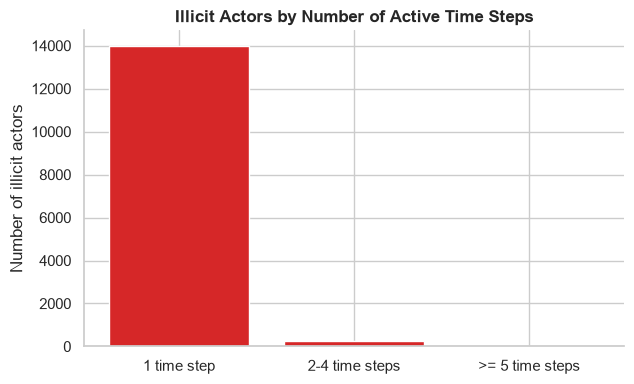

Illicit actors active in >= 5 time steps: 23


In [11]:
if combined_df is None or time_column is None or class_column is None:
    print("A combined actor table with time-step and class columns is required.")
else:
    illicit_key = next(
        (k for k in ["1", "illicit"] if resolve_class_name(k) == "Illicit"), "1"
    )
    illicit_mask = combined_df[class_column].astype(str).str.strip().str.lower().isin(
        [illicit_key, "illicit", "1"]
    )
    illicit_rows = combined_df[illicit_mask]

    time_steps_per_address = illicit_rows.groupby("address")[time_column].nunique()

    buckets = pd.cut(
        time_steps_per_address,
        bins=[0, 1, 4, float("inf")],
        labels=["1 time step", "2-4 time steps", ">= 5 time steps"],
    )
    bucket_counts = buckets.value_counts().reindex(
        ["1 time step", "2-4 time steps", ">= 5 time steps"]
    )
    display(bucket_counts.rename("illicit_actor_count").to_frame())

    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.bar(bucket_counts.index.astype(str), bucket_counts.values, color="#d62728")
    ax.set_title("Illicit Actors by Number of Active Time Steps", fontsize=12, weight="bold")
    ax.set_ylabel("Number of illicit actors")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"Illicit actors active in >= 5 time steps: {int((time_steps_per_address >= 5).sum())}")

### Address activity statistics (AddrTx / TxAddr)

Basic counts of distinct addresses that send to, and receive from, transactions —
mirrors the "number of input and output wallet addresses" statistic from the sample
Actors statistics notebook.

In [12]:
rows = []
if df_AddrTx_edgelist is not None:
    rows.append({
        "table": "AddrTx_edgelist (address -> tx)",
        "unique_addresses": df_AddrTx_edgelist["input_address"].nunique(),
        "unique_transactions": df_AddrTx_edgelist["txId"].nunique() if "txId" in df_AddrTx_edgelist.columns else np.nan,
        "rows": len(df_AddrTx_edgelist),
    })
if df_TxAddr_edgelist is not None:
    rows.append({
        "table": "TxAddr_edgelist (tx -> address)",
        "unique_addresses": df_TxAddr_edgelist["output_address"].nunique(),
        "unique_transactions": df_TxAddr_edgelist["txId"].nunique() if "txId" in df_TxAddr_edgelist.columns else np.nan,
        "rows": len(df_TxAddr_edgelist),
    })

if rows:
    display(pd.DataFrame(rows))
else:
    print("AddrTx_edgelist / TxAddr_edgelist are not available.")

,table,unique_addresses,unique_transactions,rows
0,AddrTx_edgelist (address -> tx),400212,202804,477117
1,TxAddr_edgelist (tx -> address),641043,202804,837124


### Bitcoin user entity statistics

A single real-world user can control many wallet addresses. Following the sample notebook's
"Bitcoin user entity" analysis, this section treats each **connected component** of the
undirected Addr-Addr interaction graph as one user entity (built with `networkx`), and looks
at how many addresses belong to each entity.

**Note:** `AddrAddr_edgelist.csv` can be large — this runs the full-graph computation once
and caches the result in `address_entities` / `entity_sizes` for reuse.

Total user entities (connected components): 2


,addresses_per_entity
count,2.000000
mean,411471.000000
std,581897.969228
min,7.000000
25%,205739.000000
50%,411471.000000
75%,617203.000000
max,822935.000000


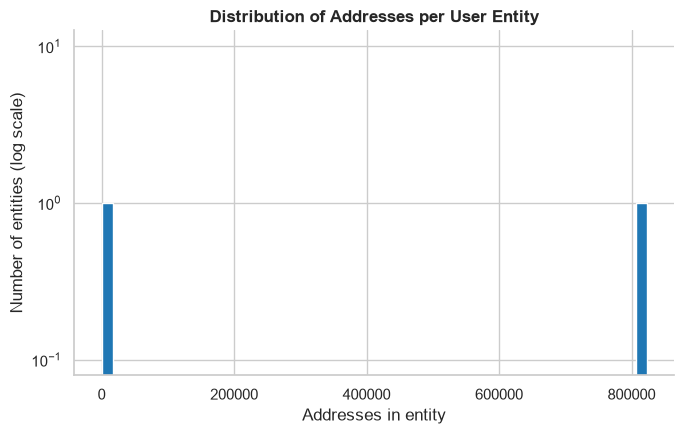

In [13]:
if df_AddrAddr_edgelist is None:
    print("AddrAddr_edgelist.csv is not available.")
else:
    full_addr_graph = nx.from_pandas_edgelist(
        df_AddrAddr_edgelist.dropna(subset=["input_address", "output_address"]),
        source="input_address",
        target="output_address",
    )

    address_entities = list(nx.connected_components(full_addr_graph))
    entity_sizes = pd.Series([len(component) for component in address_entities], name="addresses_per_entity")

    print(f"Total user entities (connected components): {len(entity_sizes):,}")
    display(entity_sizes.describe().to_frame())

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(entity_sizes, bins=50, color="#1f77b4", edgecolor="white")
    ax.set_yscale("log")
    ax.set_title("Distribution of Addresses per User Entity", fontsize=12, weight="bold")
    ax.set_xlabel("Addresses in entity")
    ax.set_ylabel("Number of entities (log scale)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

## Graph Visualization

The sample notebook visualizes the **Actor Interaction Graph (Addr-Addr graph)** for selected time steps.

The graph is directed:

- node = wallet address
- edge `input_address -> output_address` = observed interaction between addresses

Nodes are colored using the label helpers defined above (illicit / licit / unknown / no label),
and drawn with `networkx` + `matplotlib` (no external plotting service required).

Visualization time steps: [14, 32]


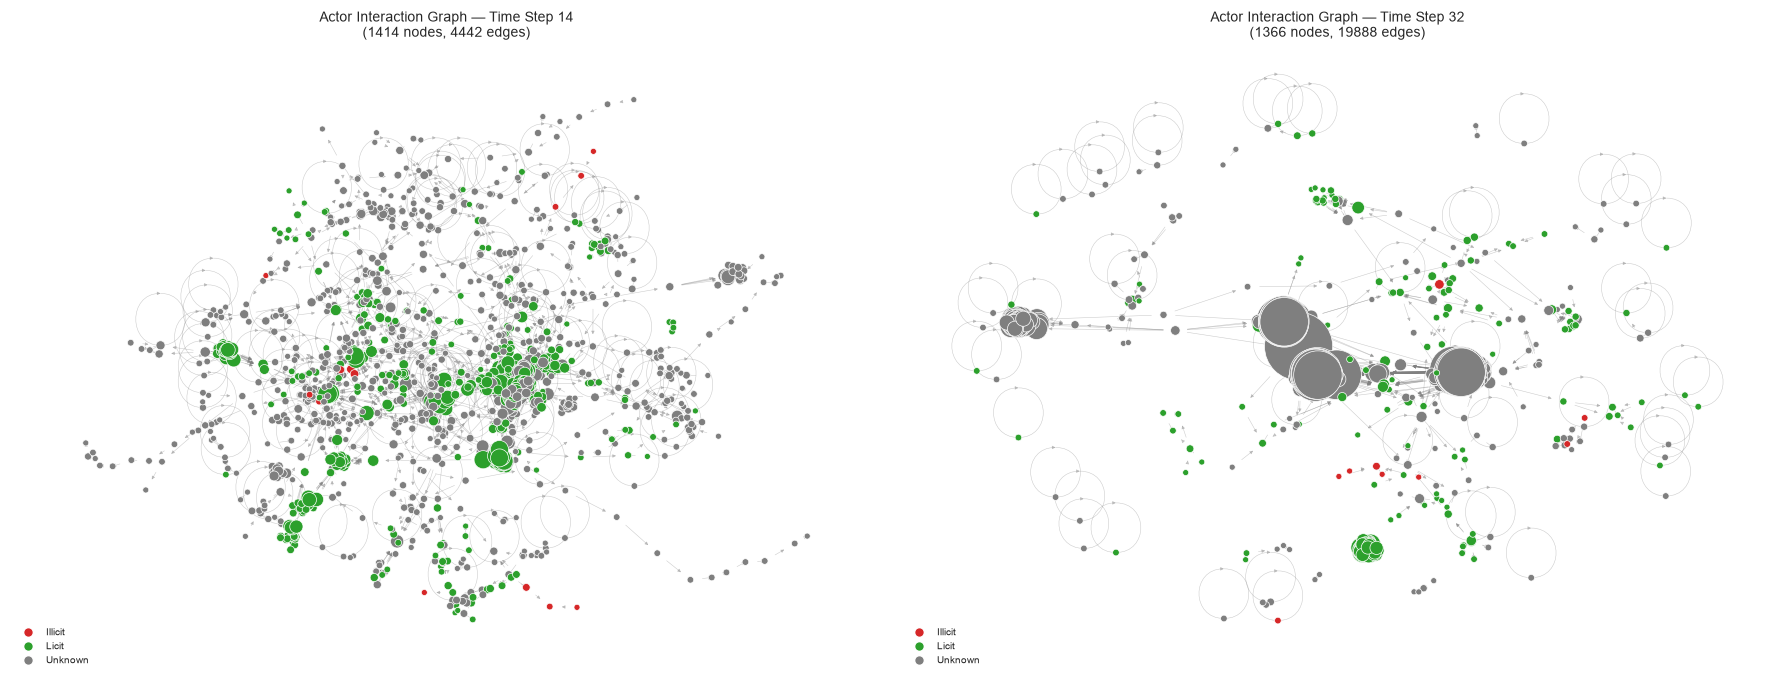

In [14]:
def build_actor_interaction_subgraph(time_step, max_nodes=1500):
    """Build a filtered directed graph of actor interactions for one time step.

    Returns a networkx.DiGraph, or None if the required inputs are missing.
    Only the visualization workload is limited (top-degree nodes kept);
    the underlying dataframes are never modified.
    """
    if df_AddrAddr_edgelist is None:
        print("AddrAddr_edgelist.csv is not available.")
        return None

    if combined_df is None or time_column is None:
        print("A combined actor table with a time-step column is required.")
        return None

    addresses = set(
        combined_df.loc[combined_df[time_column] == time_step, "address"].dropna()
    )

    if not addresses:
        print(f"No actor addresses found for time step {time_step}.")
        return None

    edges = df_AddrAddr_edgelist[
        df_AddrAddr_edgelist["input_address"].isin(addresses)
        & df_AddrAddr_edgelist["output_address"].isin(addresses)
    ][["input_address", "output_address"]].dropna()

    if edges.empty:
        print(f"No Addr-Addr edges found for time step {time_step}.")
        return None

    degree_counts = pd.concat(
        [edges["input_address"], edges["output_address"]]
    ).value_counts()

    keep_nodes = set(degree_counts.head(max_nodes).index)
    edges = edges[
        edges["input_address"].isin(keep_nodes)
        & edges["output_address"].isin(keep_nodes)
    ]

    graph = nx.from_pandas_edgelist(
        edges,
        source="input_address",
        target="output_address",
        create_using=nx.DiGraph(),
    )

    return graph


def draw_actor_interaction_graph(graph, time_step, ax, address_class_map=None, seed=42):
    """Draw a pre-built actor-interaction graph onto a matplotlib Axes using networkx.

    Nodes are colored by their actor class/label when `address_class_map` is
    provided (address -> raw label value); nodes without a known label are
    drawn in a neutral grey.
    """
    if graph is None or graph.number_of_nodes() == 0:
        ax.set_title(f"Time Step {time_step} — no data")
        ax.axis("off")
        return

    address_class_map = address_class_map or {}
    pos = nx.spring_layout(graph, seed=seed, k=0.2)

    node_degrees = dict(graph.degree())
    node_sizes = [15 + 4 * node_degrees[node] for node in graph.nodes()]
    node_labels = [address_class_map.get(node) for node in graph.nodes()]
    node_colors = [resolve_class_color(label) for label in node_labels]

    nx.draw_networkx_edges(
        graph, pos, ax=ax,
        width=0.4, alpha=0.4, edge_color="grey",
        arrows=True, arrowsize=5, arrowstyle="-|>",
    )
    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        node_size=node_sizes, node_color=node_colors,
        linewidths=0.5, edgecolors="white",
    )

    ax.set_title(
        f"Actor Interaction Graph — Time Step {time_step}\n"
        f"({graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges)",
        fontsize=10,
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    present_labels = sorted(set(node_labels), key=lambda v: resolve_class_name(v))
    legend_handles = [
        plt.Line2D(
            [0], [0], marker="o", linestyle="", markersize=7,
            markerfacecolor=resolve_class_color(label),
            markeredgecolor="white", label=resolve_class_name(label),
        )
        for label in present_labels
    ]
    if legend_handles:
        ax.legend(handles=legend_handles, loc="lower left", fontsize=7, frameon=False)


def plot_actor_interaction_graph(time_step, max_nodes=1500, class_column=None):
    """Build and draw the actor-interaction graph for a single time step (standalone figure)."""
    graph = build_actor_interaction_subgraph(time_step, max_nodes=max_nodes)
    address_class_map = build_address_class_map(combined_df, class_column)

    fig, ax = plt.subplots(figsize=(9, 7))
    draw_actor_interaction_graph(graph, time_step, ax=ax, address_class_map=address_class_map)
    plt.tight_layout()
    plt.show()


def plot_actor_interaction_graphs(time_steps, max_nodes=1500, class_column=None):
    """Build and draw actor-interaction graphs for several time steps side by side,
    with nodes colored by actor class/label when `class_column` is available.
    """
    if not time_steps:
        print("No time steps to visualize.")
        return

    address_class_map = build_address_class_map(combined_df, class_column)

    fig, axes = plt.subplots(
        1, len(time_steps), figsize=(9 * len(time_steps), 7), squeeze=False
    )
    axes = axes[0]

    for step, ax in zip(time_steps, axes):
        graph = build_actor_interaction_subgraph(step, max_nodes=max_nodes)
        draw_actor_interaction_graph(graph, step, ax=ax, address_class_map=address_class_map)

    plt.tight_layout()
    plt.show()


preferred_steps = [
    step for step in [14, 32]
    if combined_df is not None and time_column is not None
    and step in set(combined_df[time_column].dropna())
]

if not preferred_steps and combined_df is not None and time_column is not None:
    preferred_steps = combined_df[time_column].dropna().drop_duplicates().head(2).tolist()

print("Visualization time steps:", preferred_steps)

plot_actor_interaction_graphs(preferred_steps, class_column=class_column)

## Actor Feature Analysis

The sample statistics notebook notes that some numeric features correlate well with the
illicit/licit label (useful for classification and explainability) while others do not. The
cells below compute that directly instead of relying on a fixed list, using a reusable
helper (also reused for the Transactions dataset further below):

1. Missing-value overview across numeric features.
2. Correlation of every numeric feature with the illicit/licit label.
3. A correlation heatmap for the most informative features.
4. Distribution comparison (illicit vs licit) for the top correlated features.

In [15]:
def missing_value_report(df, feature_columns, top_n=15):
    missing = df[feature_columns].isna().mean().sort_values(ascending=False) * 100
    missing = missing[missing > 0].head(top_n)
    if missing.empty:
        print("No missing values among the numeric feature columns.")
        return
    display(missing.round(2).rename("missing_%").to_frame())


def class_correlation_report(df, class_column, feature_columns, illicit_key="1", licit_key="2"):
    """Correlate numeric features with a binary illicit(1)/licit(0) label,
    dropping rows labeled anything else (e.g. unknown)."""
    labels = df[class_column].astype(str).str.strip().str.lower()
    mask = labels.isin([illicit_key, "illicit", licit_key, "licit"])
    sub = df.loc[mask, feature_columns].copy()
    binary_label = labels.loc[mask].isin([illicit_key, "illicit"]).astype(int)
    sub = sub.select_dtypes(include=np.number)
    return sub.corrwith(binary_label).dropna().sort_values(ascending=False)


def plot_top_correlations(correlations, top_n=10, title="Top correlated features"):
    if correlations.empty:
        print("No correlations to plot.")
        return

    combined = pd.concat([correlations.head(top_n), correlations.tail(top_n)]).drop_duplicates()
    combined = combined.sort_values()
    colors = ["#2ca02c" if v < 0 else "#d62728" for v in combined.values]

    fig, ax = plt.subplots(figsize=(7.5, max(4, 0.32 * len(combined))))
    ax.barh(combined.index, combined.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel("Correlation with illicit label (1 = illicit)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

In [16]:
if df_wallets_features is None or not actor_numeric_columns:
    print("Numeric actor features are not available.")
else:
    print("Missing-value overview (top offenders):")
    missing_value_report(df_wallets_features, actor_numeric_columns)

Missing-value overview (top offenders):
No missing values among the numeric feature columns.


Features showing the strongest correlation with the illicit label:


,correlation
first_sent_block,0.200315
fees_max,0.110809
first_received_block,0.101114
first_block_appeared_in,0.093848
fees_mean,0.049461
fees_median,0.049382
last_block_appeared_in,0.036554
fees_as_share_median,0.009147
fees_as_share_mean,0.005242
fees_as_share_min,-0.003654



Features showing the strongest correlation with the licit label (negative values):


,correlation
blocks_btwn_txs_median,-0.065353
transacted_w_address_mean,-0.066966
blocks_btwn_output_txs_median,-0.070323
blocks_btwn_txs_mean,-0.071322
blocks_btwn_output_txs_mean,-0.074471
blocks_btwn_output_txs_total,-0.088600
blocks_btwn_txs_total,-0.088699
lifetime_in_blocks,-0.088700
blocks_btwn_txs_max,-0.090054
blocks_btwn_output_txs_max,-0.092099


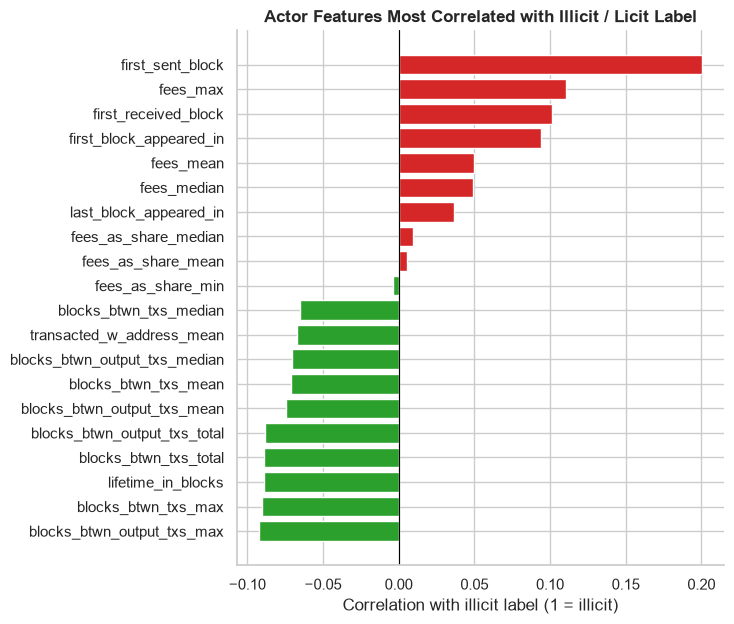

In [17]:
if combined_df is None or class_column is None or not actor_numeric_columns:
    print("Combined actor table / class column / numeric features are required for correlation analysis.")
    actor_feature_correlations = pd.Series(dtype=float)
else:
    actor_feature_correlations = class_correlation_report(
        combined_df, class_column, actor_numeric_columns
    )

    print("Features showing the strongest correlation with the illicit label:")
    display(actor_feature_correlations.head(10).rename("correlation").to_frame())

    print("\nFeatures showing the strongest correlation with the licit label (negative values):")
    display(actor_feature_correlations.tail(10).rename("correlation").to_frame())

    plot_top_correlations(
        actor_feature_correlations, top_n=10,
        title="Actor Features Most Correlated with Illicit / Licit Label",
    )

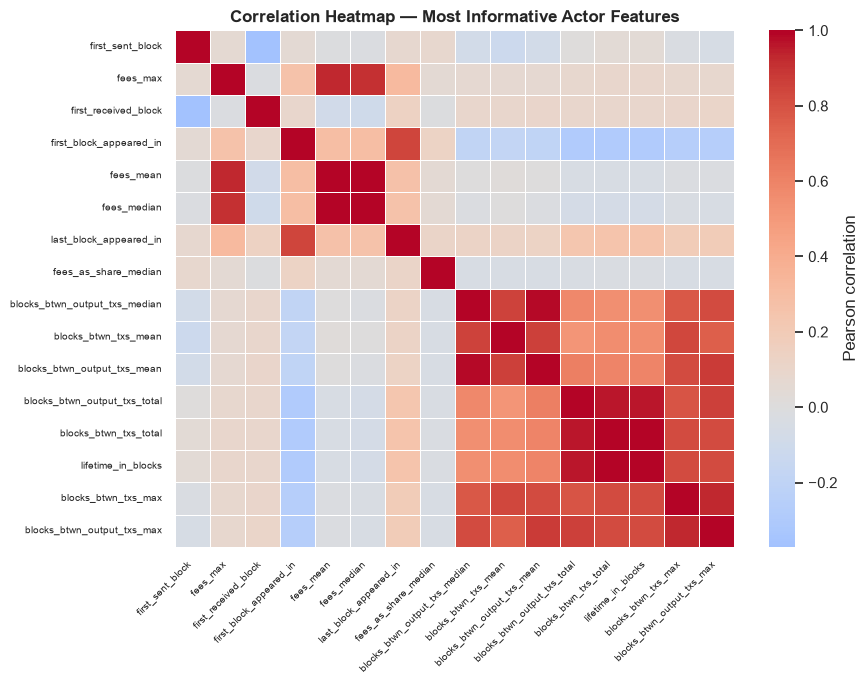

In [18]:
if actor_feature_correlations.empty:
    print("No correlated features available for the heatmap.")
else:
    top_features = pd.concat(
        [actor_feature_correlations.head(8), actor_feature_correlations.tail(8)]
    ).drop_duplicates().index.tolist()

    corr_matrix = combined_df[top_features].corr()

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(
        corr_matrix, ax=ax, cmap="coolwarm", center=0,
        annot=False, linewidths=0.4, cbar_kws={"label": "Pearson correlation"},
    )
    ax.set_title("Correlation Heatmap — Most Informative Actor Features", fontsize=12, weight="bold")
    plt.xticks(rotation=45, ha="right", fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    plt.show()

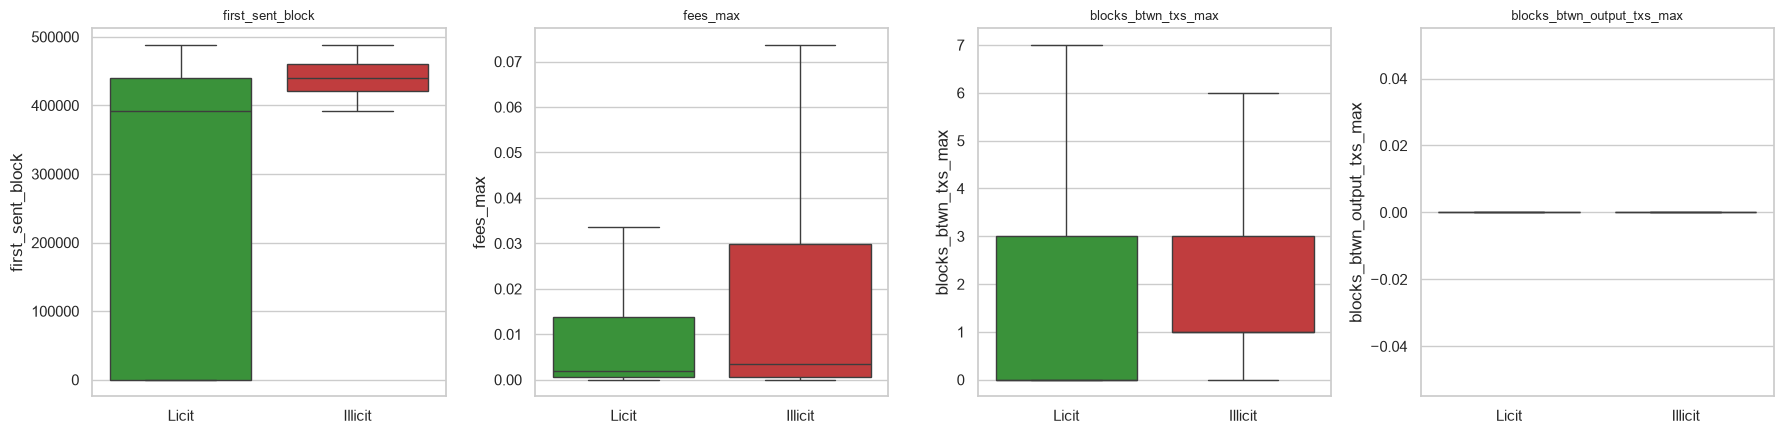

In [19]:
if actor_feature_correlations.empty:
    print("No correlated features available for the distribution comparison.")
else:
    top4 = pd.concat(
        [actor_feature_correlations.head(2), actor_feature_correlations.tail(2)]
    ).index.tolist()

    plot_df = combined_df[combined_df[class_column].astype(str).str.strip().str.lower().isin(
        ["1", "illicit", "2", "licit"]
    )].copy()
    plot_df["label_name"] = plot_df[class_column].apply(resolve_class_name)

    fig, axes = plt.subplots(1, len(top4), figsize=(4.5 * len(top4), 4.5))
    if len(top4) == 1:
        axes = [axes]

    for feature, ax in zip(top4, axes):
        sns.boxplot(
            data=plot_df, x="label_name", y=feature, ax=ax,
            hue="label_name",
            palette={"Illicit": "#d62728", "Licit": "#2ca02c"},
            showfliers=False, legend=False,
        )
        ax.set_title(feature, fontsize=9)
        ax.set_xlabel("")

    plt.tight_layout()
    plt.show()

## Transactions Dataset Overview

The project also contains a separate Transactions dataset:

- `txs_features.csv` — numeric features per transaction
- `txs_classes.csv` — class label per transaction (`1`=illicit, `2`=licit, `3`=unknown)
- `txs_edgelist.csv` — transaction/transaction graph

The notebook first inventories every discovered CSV generically, then loads the three files
above by name for the statistics and feature-analysis sections that follow.

In [20]:
transaction_frames = {}

for stem, path in sorted(transaction_paths.items()):
    df = pd.read_csv(path)
    transaction_frames[stem] = df

    print(f"\n{path.name}")
    print(f"Shape: {df.shape}")
    display(df.head())

transaction_schema_rows = []
for name, df in transaction_frames.items():
    transaction_schema_rows.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
    })

if transaction_schema_rows:
    display(pd.DataFrame(transaction_schema_rows))

df_txs_features = transaction_frames.get("txs_features")
df_txs_classes = transaction_frames.get("txs_classes")
df_txs_edgelist = transaction_frames.get("txs_edgelist")


txs_classes.csv
Shape: (203769, 2)


,txId,class
0,3321,3
1,11108,3
2,51816,3
3,68869,2
4,89273,2



txs_edgelist.csv
Shape: (234355, 2)


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206



txs_features.csv
Shape: (203769, 184)


,txId,Time step,Local_feature_1,Local_feature_2,Local_feature_3,Local_feature_4,Local_feature_5,Local_feature_6,Local_feature_7,Local_feature_8,Local_feature_9,Local_feature_10,Local_feature_11,Local_feature_12,Local_feature_13,Local_feature_14,Local_feature_15,Local_feature_16,Local_feature_17,Local_feature_18,Local_feature_19,Local_feature_20,Local_feature_21,Local_feature_22,Local_feature_23,Local_feature_24,Local_feature_25,Local_feature_26,Local_feature_27,Local_feature_28,Local_feature_29,Local_feature_30,Local_feature_31,Local_feature_32,Local_feature_33,Local_feature_34,Local_feature_35,Local_feature_36,Local_feature_37,Local_feature_38,Local_feature_39,Local_feature_40,Local_feature_41,Local_feature_42,Local_feature_43,Local_feature_44,Local_feature_45,Local_feature_46,Local_feature_47,Local_feature_48,...,Aggregate_feature_40,Aggregate_feature_41,Aggregate_feature_42,Aggregate_feature_43,Aggregate_feature_44,Aggregate_feature_45,Aggregate_feature_46,Aggregate_feature_47,Aggregate_feature_48,Aggregate_feature_49,Aggregate_feature_50,Aggregate_feature_51,Aggregate_feature_52,Aggregate_feature_53,Aggregate_feature_54,Aggregate_feature_55,Aggregate_feature_56,Aggregate_feature_57,Aggregate_feature_58,Aggregate_feature_59,Aggregate_feature_60,Aggregate_feature_61,Aggregate_feature_62,Aggregate_feature_63,Aggregate_feature_64,Aggregate_feature_65,Aggregate_feature_66,Aggregate_feature_67,Aggregate_feature_68,Aggregate_feature_69,Aggregate_feature_70,Aggregate_feature_71,Aggregate_feature_72,in_txs_degree,out_txs_degree,total_BTC,fees,size,num_input_addresses,num_output_addresses,in_BTC_min,in_BTC_max,in_BTC_mean,in_BTC_median,in_BTC_total,out_BTC_min,out_BTC_max,out_BTC_mean,out_BTC_median,out_BTC_total
0,3321,1,-0.169615,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160199,-0.166062,-0.049707,-0.162507,-0.028741,-0.035391,-0.042955,-0.013282,-0.042183,-0.168770,-0.171416,-0.172277,-1.373657,-1.371460,-0.139663,-0.148869,-0.080147,-0.155604,-0.010763,-0.012107,-0.139665,-0.148864,-0.080147,-0.155604,-0.010669,-0.012005,-0.024668,-0.031272,-0.023045,-0.026214,0.001428,0.001483,-0.226298,-0.238504,-0.075256,-0.234053,0.037468,0.043444,-0.226681,-0.242726,-0.097895,...,-0.187518,-1.159649,-1.160129,-1.371865,-1.352048,-0.295364,-1.401266,-0.975738,-0.975237,-0.158413,-0.451760,-0.420758,-0.430701,-1.015963,-1.016230,-0.968903,-1.943850,-1.059868,-1.678997,0.185597,0.185492,-0.003773,-0.562664,-0.577099,-0.500080,0.241128,0.241406,-0.098889,-0.087490,-0.084674,-0.140597,1.519700,1.521399,1.0,0.0,0.533972,0.0001,225.0,1.0,2.0,0.534072,0.534072,0.534072,0.534072,0.534072,1.668990e-01,0.367074,0.266986,0.266986,0.533972
1,11108,1,-0.137586,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.127429,-0.133751,-0.049707,-0.129773,-0.028741,-0.035391,-0.042955,-0.013282,-0.003952,-0.138560,-0.139821,-0.134358,0.887058,0.884557,-0.139564,-0.148805,-0.080147,-0.155520,-0.010763,-0.012107,-0.139566,-0.148800,-0.080147,-0.155520,-0.010669,-0.012005,-0.024530,-0.031142,-0.023045,-0.026079,0.001428,0.001483,-0.226837,-0.239012,-0.075256,-0.234581,0.037468,0.043444,-0.226829,-0.242870,-0.097895,...,-0.192920,1.064205,1.063787,-1.373782,-1.352048,-0.290966,-1.402204,-0.975738,-0.975237,-0.168742,-0.429352,-0.389444,-0.412059,-1.015963,-1.016230,-0.968903,-1.943850,-1.059868,-1.678997,0.185597,0.185492,-0.216814,-0.605631,-0.562153,-0.600999,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,1.0,1.0,5.611778,0.0001,225.0,1.0,2.0,5.611878,5.611878,5.611878,5.611878,5.611878,5.861940e-01,5.025584,2.805889,2.805889,5.611778
2,51816,1,-0.170103,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.160699,-0.166555,-0.049707,-0.163006,-0.028741,-0.035391,-0.042955,-0.013282,-0.036613,-0.169668,-0.172904,-0.172855,-1.373657,-1.371460,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139732,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.

,table,rows,columns,missing_cells,duplicate_rows
0,txs_classes,203769,2,0,0
1,txs_edgelist,234355,2,0,0
2,txs_features,203769,184,16405,0


### Transactions class distribution & time-step coverage

Mirrors the Actors class-distribution and time-step sections above, applied to
`txs_features.csv` / `txs_classes.csv`.

In [21]:
txs_class_column = None
txs_time_column = None

if df_txs_features is not None and df_txs_classes is not None:
    txs_class_column = detect_column(df_txs_classes, ["class", "Class", "label", "Label"])

    if txs_class_column is not None and txs_class_column not in df_txs_features.columns:
        df_txs_features = df_txs_features.merge(
            df_txs_classes[["txId", txs_class_column]], on="txId", how="left"
        )

    txs_time_column = detect_column(
        df_txs_features, ["Time step", "time_step", "TimeStep", "timestep"]
    )

    print(f"txs_class_column = {txs_class_column!r}")
    print(f"txs_time_column  = {txs_time_column!r}")
else:
    print("txs_features.csv / txs_classes.csv are not both available.")

txs_class_column = 'class'
txs_time_column  = 'Time step'


,class,count,percentage,label_name
0,1,4545,2.23,Illicit
1,2,42019,20.62,Licit
2,3,157205,77.15,Unknown


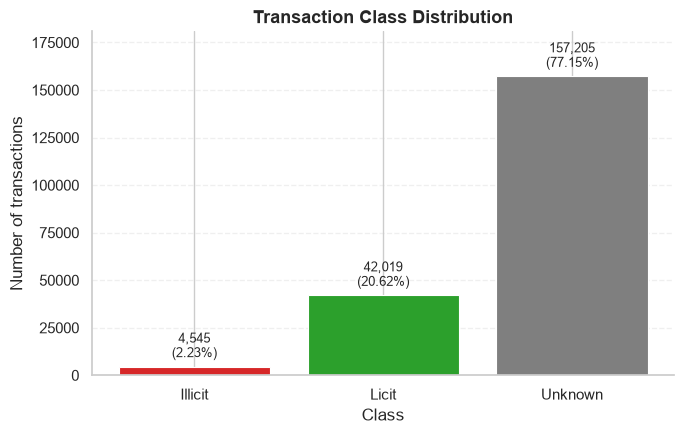

In [22]:
if df_txs_features is None or txs_class_column is None:
    print("Transaction class information is not available.")
else:
    txs_class_counts = (
        df_txs_features[txs_class_column]
        .value_counts(dropna=False)
        .rename_axis(txs_class_column)
        .reset_index(name="count")
        .sort_values(txs_class_column)
        .reset_index(drop=True)
    )
    txs_class_counts["percentage"] = (
        txs_class_counts["count"] / txs_class_counts["count"].sum() * 100
    ).round(2)
    txs_class_counts["label_name"] = txs_class_counts[txs_class_column].apply(resolve_class_name)
    display(txs_class_counts)

    colors = txs_class_counts[txs_class_column].apply(resolve_class_color)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(
        txs_class_counts["label_name"], txs_class_counts["count"],
        color=colors, edgecolor="white", linewidth=0.8,
    )
    for bar, count, pct in zip(bars, txs_class_counts["count"], txs_class_counts["percentage"]):
        ax.annotate(
            f"{count:,}\n({pct}%)",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4), textcoords="offset points",
            ha="center", va="bottom", fontsize=9,
        )
    ax.set_title("Transaction Class Distribution", fontsize=13, weight="bold")
    ax.set_xlabel(txs_class_column.capitalize())
    ax.set_ylabel("Number of transactions")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.margins(y=0.15)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

class,1,2,3,Total
Time step,,,,
1,17,2130,5733,7880
2,18,1099,3427,4544
3,11,1268,5342,6621
4,30,1410,4253,5693
5,8,1874,4921,6803
6,5,480,3843,4328
7,102,1101,4845,6048
8,67,1098,3292,4457
9,248,530,4218,4996


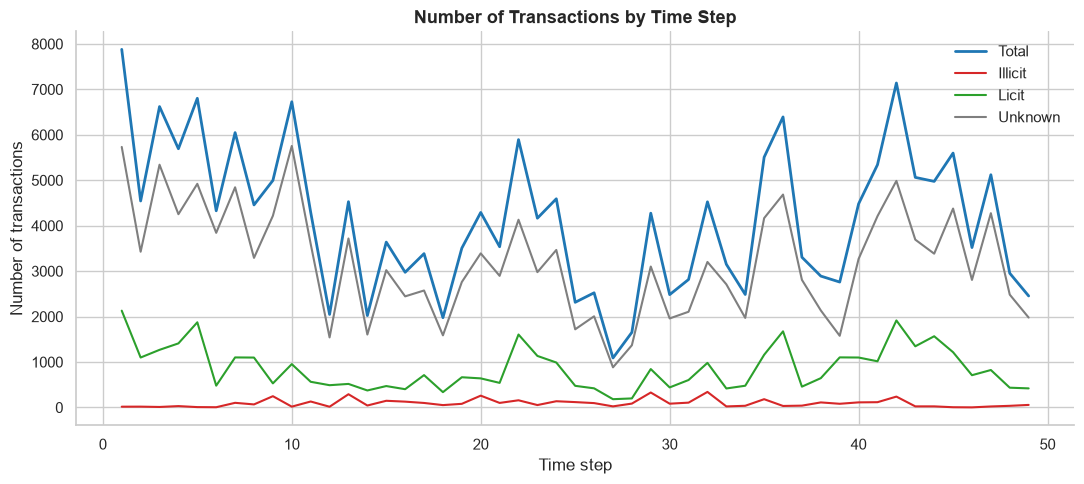

In [23]:
if df_txs_features is None or txs_time_column is None or txs_class_column is None:
    print("A time-step column is not available for the transactions table.")
else:
    grouped_txs = (
        df_txs_features[[txs_time_column, txs_class_column]]
        .groupby([txs_time_column, txs_class_column])
        .size()
        .rename("count")
        .reset_index()
    )

    txs_pivot = grouped_txs.pivot(
        index=txs_time_column, columns=txs_class_column, values="count"
    ).fillna(0)
    txs_pivot["Total"] = txs_pivot.sum(axis=1)
    display(txs_pivot.head(10))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(txs_pivot.index, txs_pivot["Total"], color="#1f77b4", label="Total", linewidth=2)
    for label_value in txs_pivot.columns:
        if label_value == "Total":
            continue
        ax.plot(
            txs_pivot.index, txs_pivot[label_value],
            color=resolve_class_color(label_value),
            label=resolve_class_name(label_value),
            linewidth=1.5,
        )
    ax.set_title("Number of Transactions by Time Step", fontsize=13, weight="bold")
    ax.set_xlabel(txs_time_column)
    ax.set_ylabel("Number of transactions")
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

## Transaction Feature Analysis

Same approach as the Actor Feature Analysis section above, reusing the
`missing_value_report`, `class_correlation_report` and `plot_top_correlations` helpers
on `txs_features.csv`.

In [24]:
TXS_NON_FEATURE_COLUMNS = {"txId", "class", "Time step", "time_step"}

if df_txs_features is None:
    txs_numeric_columns = []
    print("txs_features.csv is not available.")
else:
    txs_numeric_columns = [
        col
        for col in df_txs_features.select_dtypes(include=np.number).columns
        if col not in TXS_NON_FEATURE_COLUMNS
    ]
    print(f"Numeric transaction feature columns: {len(txs_numeric_columns)}")

    print("\nMissing-value overview (top offenders):")
    missing_value_report(df_txs_features, txs_numeric_columns)

Numeric transaction feature columns: 182

Missing-value overview (top offenders):


,missing_%
in_BTC_total,0.47
out_BTC_min,0.47
out_BTC_max,0.47
out_BTC_mean,0.47
out_BTC_median,0.47
out_txs_degree,0.47
in_txs_degree,0.47
total_BTC,0.47
fees,0.47
size,0.47


Transaction features showing the strongest correlation with the illicit label:


,correlation
Aggregate_feature_49,0.191936
Aggregate_feature_61,0.152966
Aggregate_feature_55,0.135878
Aggregate_feature_19,0.075631
Local_feature_20,0.044680
Local_feature_21,0.042422
Aggregate_feature_37,0.040726
Local_feature_12,0.035218
Aggregate_feature_58,0.032712
Local_feature_13,0.025595



Transaction features showing the strongest correlation with the licit label (negative values):


,correlation
Aggregate_feature_63,-0.135176
Aggregate_feature_21,-0.137636
Local_feature_54,-0.142125
Local_feature_52,-0.171799
Local_feature_91,-0.185804
Aggregate_feature_57,-0.187232
Local_feature_90,-0.221294
Local_feature_55,-0.227146
Local_feature_89,-0.227629
Local_feature_53,-0.261472


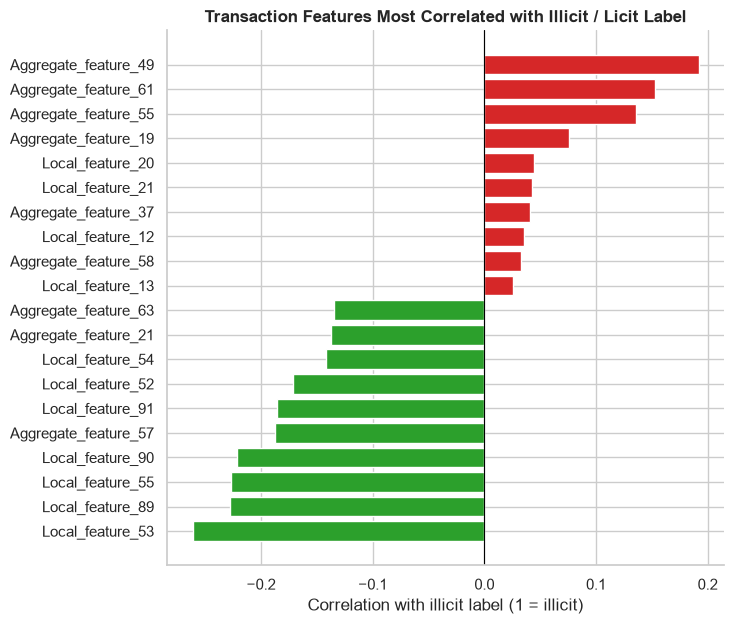

In [25]:
if df_txs_features is None or txs_class_column is None or not txs_numeric_columns:
    print("Transaction features / class column are required for correlation analysis.")
    txs_feature_correlations = pd.Series(dtype=float)
else:
    txs_feature_correlations = class_correlation_report(
        df_txs_features, txs_class_column, txs_numeric_columns
    )

    print("Transaction features showing the strongest correlation with the illicit label:")
    display(txs_feature_correlations.head(10).rename("correlation").to_frame())

    print("\nTransaction features showing the strongest correlation with the licit label (negative values):")
    display(txs_feature_correlations.tail(10).rename("correlation").to_frame())

    plot_top_correlations(
        txs_feature_correlations, top_n=10,
        title="Transaction Features Most Correlated with Illicit / Licit Label",
    )

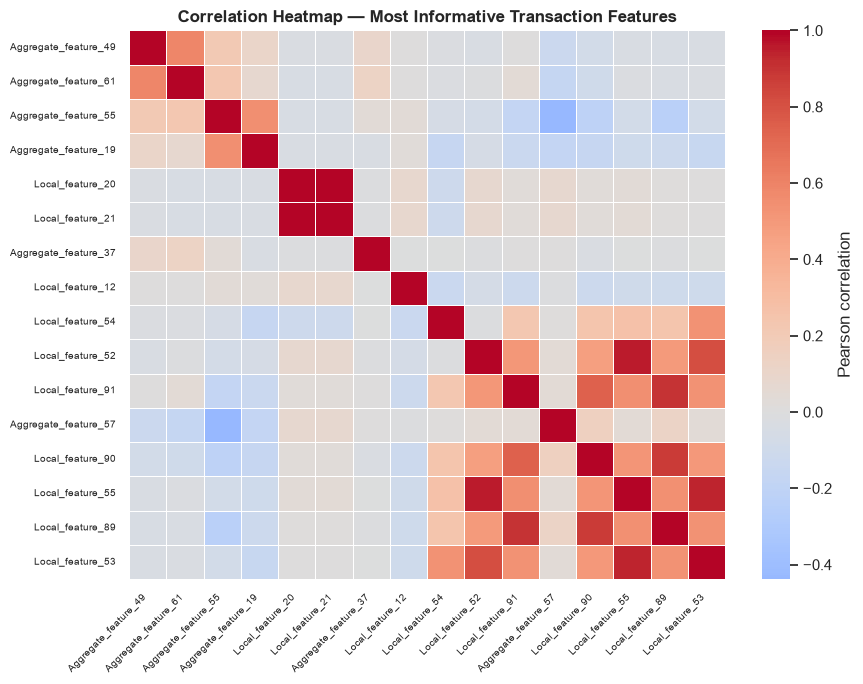

In [26]:
if txs_feature_correlations.empty:
    print("No correlated transaction features available for the heatmap.")
else:
    txs_top_features = pd.concat(
        [txs_feature_correlations.head(8), txs_feature_correlations.tail(8)]
    ).drop_duplicates().index.tolist()

    txs_corr_matrix = df_txs_features[txs_top_features].corr()

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(
        txs_corr_matrix, ax=ax, cmap="coolwarm", center=0,
        annot=False, linewidths=0.4, cbar_kws={"label": "Pearson correlation"},
    )
    ax.set_title("Correlation Heatmap — Most Informative Transaction Features", fontsize=12, weight="bold")
    plt.xticks(rotation=45, ha="right", fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    plt.show()

## Summary

This notebook now documents:

1. Which Actors and Transactions CSV files are present, and their size.
2. The size and structure of the main Actors tables (rows, columns, missing/duplicate counts).
3. Column types, missing values, and unique-value counts.
4. A representative actor across the feature/class/edge tables and its linked transactions.
5. Numeric feature summary statistics for `wallets_features.csv`.
6. Actor class distribution and time-step coverage.
7. Illicit-actor persistence across time steps (1 / 2-4 / >=5 time steps).
8. Unique input/output address counts from `AddrTx_edgelist` / `TxAddr_edgelist`.
9. Bitcoin "user entity" statistics via connected components of the Addr-Addr graph.
10. Actor Interaction Graph visualizations (networkx + matplotlib), colored by class label.
11. Actor feature analysis: missing values, correlation with the illicit/licit label,
    a correlation heatmap, and illicit-vs-licit distribution comparisons for the most
    informative features.
12. A generic schema overview for the Transactions dataset, plus transaction class
    distribution, time-step coverage, and the same feature-correlation analysis applied
    to `txs_features.csv`.

These outputs provide the dataset baseline for the next preprocessing, graph construction,
clustering, and behavioral analysis notebooks.